<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Beyond "how close": scoring a forecast at your stations 🇬🇷
### HNMS open station data × ECMWF IFS and AIFS · deterministic and ensemble · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/hnms_scores.ipynb)

The companion notebook [*Your stations, our forecast*](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/hnms_vs_ifs.ipynb) asks one question: how close was the
forecast to each station? That is a start, but a crude one. One number cannot say *why* a forecast was off (a constant
offset? too little variation? the wrong timing?), whether it got worse with lead time, whether it beat a forecast
anyone could make, whether it caught the rain, or how good its probabilities were.

This notebook works through the standard toolkit of forecast verification on **two days** of HNMS stations:

| Section | Question | Scores |
|---|---|---|
| 3 | Why was it off? | bias, RMSE, correlation, and the MSE split into bias, variability and timing |
| 4 | How fast does it get worse? Is it worth having? | RMSE and bias by lead time; skill against persistence |
| 5 | When and where? | error by hour of day; by station type (coast, inland, mountain) |
| 6 | Did it catch the events? | hits, misses, false alarms: POD, FAR, frequency bias, ETS for rain and wind |
| 7 | How good were the probabilities? | IFS ENS and AIFS ENS: CRPS, spread against error, rank histogram |

Both models are taken at the same 0.25° grid, so the comparison is about the model and not the grid. **Two days are
an example, not a verdict:** section 8 shows how to run it for longer periods.

| Data | What this notebook uses | Licence |
|---|---|---|
| HNMS automatic weather stations ([data.gov.gr](https://data.gov.gr), EU High-Value Dataset) | 2 m temperature, 10 m wind, rain, every 5 minutes, last ~3 days | CC BY 4.0, © HNMS |
| [ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data): IFS and AIFS Single, 0.25° | 2 m temperature, 10 m wind, precipitation; 00 UTC runs, 6-hourly | CC BY 4.0, © ECMWF |
| ECMWF open data: IFS ENS and AIFS ENS, 0.25°, 50 members each | 2 m temperature, one run | CC BY 4.0, © ECMWF |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools, and pandas.

*Press **Runtime → Run all**. It downloads about 400 MB of forecasts, so allow 10 to 15 minutes.*

> Not an official ECMWF or HNMS product: a worked example for the ECMWF liaison visit to HNMS, November 2026.
> ECMWF's own verification, over the globe and many months, is at
> [ecmwf.int/en/forecasts/quality-our-forecasts](https://www.ecmwf.int/en/forecasts/quality-our-forecasts).

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[ecmwf-opendata]" ecmwf-opendata

## 1 · Settings, and the HNMS stations

In [2]:
# ---- settings: change these and run again ------------------------------------------------------------------
END = None          # last verified time, e.g. "2026-11-22T18:00"; None = the newest the stations allow
DAYS = 2            # length of the verified period (days). More days = more forecast runs to download
MAX_LEAD = 96       # longest lead time scored (hours); every 00 UTC run that reaches the period is used
RAIN = [1, 5]       # rain thresholds (mm in 6 hours) for the yes/no scores
WIND = 8            # wind threshold (m/s) for the yes/no scores
LAPSE = 0.0065      # move forecast temperature to the station's height at 6.5 °C per km (0 = off)
# ---------------------------------------------------------------------------------------------------------------

import pyproj                     # import before earthkit.data (avoids a crash at exit)
import io, os, time
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, requests
import earthkit.data as ekd
import matplotlib.pyplot as plt
from ecmwf.opendata import Client
BOX = dict(north=42.2, south=34.4, west=19.0, east=30.0)
COLOURS = {"IFS": "#1d2230", "AIFS": "#7b3294", "persistence": "#9a9a9a"}

In [3]:
# the HNMS stations on data.gov.gr (a CKAN catalogue: one dataset per station), and their positions
API = "https://data.gov.gr/api/3/action/package_search"
r = requests.get(API, params={"q": "Μετεωρολογικά Δεδομένα σταθμού", "rows": 200}, timeout=60).json()["result"]
files = {}
for p in r["results"]:
    if "ΕΜΥ" in ((p.get("organization") or {}).get("title") or ""):            # ΕΜΥ = HNMS
        url = next(x["url"] for x in p["resources"] if x["url"].endswith(".dat"))
        files[url.rsplit("_", 1)[1][:3]] = url
stations = pd.read_csv("https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/greece/hnms_stations.csv", dtype={"id": str})
stations = stations[stations.id.isin(files)].reset_index(drop=True)
print(f"{len(stations)} HNMS stations with a position")

75 HNMS stations with a position


In [4]:
# the end of each station file: temperature, wind and rain every 5 minutes
COLS = {"Temp_Dry_5min": "t", "Wind_Speed_Avg_5min": "wind", "Prec_Sum_1_5min": "rain"}
TAIL = int(100_000 * (DAYS + 2))        # bytes from the end of each file (about 95 kB a day): the period, a day for persistence, and a margin

def ranged(s, url, first, last="", limit=90):
    """bytes first-last of a file, giving up after `limit` seconds (a slow connection is retried, not waited on)"""
    t0, out = time.time(), b""
    with s.get(url, headers={"Range": f"bytes={first}-{last}"}, stream=True, timeout=30) as r:
        size = int(r.headers["Content-Range"].split("/")[1])
        for chunk in r.iter_content(65536):
            out += chunk
            if time.time() - t0 > limit: raise TimeoutError("too slow")
    return out.decode("utf-8", "replace"), size

def fetch(sid, tries=5):
    for k in range(tries):                                           # the server sometimes drops a connection
        try:
            s, url = requests.Session(), files[sid]
            head, size = ranged(s, url, 0, 3999)
            header = head.splitlines()[0].split(",")
            rows = ranged(s, url, max(0, size - TAIL))[0].splitlines()[1:]
            d = pd.read_csv(io.StringIO("\n".join(rows)), names=header, dtype=str,
                            usecols=lambda c: c in COLS or c == "yyyyMMddHHmm")
            d = d.rename(columns=COLS)
            for c in COLS.values():
                d[c] = pd.to_numeric(d.get(c), errors="coerce")       # "/////" = missing
            d["time"] = pd.to_datetime(d.yyyyMMddHHmm, format="%Y%m%d%H%M")   # HNMS clock = UTC
            d["id"] = sid
            return d[["id", "time", *COLS.values()]]
        except Exception as err:
            last = err
    print(f"station {sid} skipped ({type(last).__name__})")
    return pd.DataFrame(columns=["id", "time", *COLS.values()])

with ThreadPoolExecutor(8) as pool:
    obs = pd.concat(pool.map(fetch, stations.id), ignore_index=True)
# plain range checks; a real verification would use the service's own quality control
obs.loc[~obs.t.between(-40, 55), "t"] = np.nan
obs.loc[~obs.wind.between(0, 60), "wind"] = np.nan
obs.loc[~obs.rain.between(0, 50), "rain"] = np.nan

newest = obs.groupby("id").time.max().median().floor("6h")
END = pd.Timestamp(END) if END else newest
START = END - pd.Timedelta(days=DAYS)
print(f"{obs.id.nunique()} stations, {len(obs):,} records. Verified period: {START:%a %d %b %H} to {END:%a %d %b %H} UTC")

75 stations, 91,386 records. Verified period: Sat 21 Nov 12 to Mon 23 Nov 12 UTC


In [5]:
# observations at each 6-hourly verifying time
#   temperature and wind: the 5-minute record at the hour;  rain: the sum of the 72 five-minute records before it
#   persistence ("yesterday's weather"): the same observation 24 hours earlier, a forecast anyone can make
times = pd.date_range(START, END, freq="6h")
ob = {}
for sid, d in obs.groupby("id"):
    d = d.drop_duplicates("time").set_index("time").sort_index()
    at = d[["t", "wind"]].reindex(times.union(times - pd.Timedelta(hours=24)))
    r = d.rain.resample("6h", closed="right", label="right")
    rain6 = r.sum(min_count=1).where(r.count() >= 66)              # at least 66 of 72 records, or no value
    for v in times:
        p = v - pd.Timedelta(hours=24)
        ob[sid, v] = dict(t=at.t.get(v), wind=at.wind.get(v), rain=rain6.get(v),
                          t_p=at.t.get(p), wind_p=at.wind.get(p), rain_p=rain6.get(p))
print(f"{len(times)} verifying times, {sum(pd.notna(x['t']) for x in ob.values()):,} temperature observations")

9 verifying times, 630 temperature observations


## 2 · The forecasts: IFS and AIFS Single, every run that reaches the period

In [6]:
# forecasts: every 00 UTC run that reaches the period within MAX_LEAD hours, IFS and AIFS Single, 0.25°
#   data.ecmwf.int keeps the last few days; older runs come from the cloud mirrors (the archive goes back to 2023)
def get(target, limit=600, **req):
    """download with ecmwf-opendata, once: a mirror that errors or takes longer than `limit` s hands over to the next"""
    if os.path.exists(target): return target                       # already downloaded in this session
    for source in ("google", "ecmwf", "aws"):      # Colab runs on Google Cloud: its mirror is the fastest there
        part = f"{target}.{source}.part"
        job = ThreadPoolExecutor(1).submit(Client(source).retrieve, target=part, **req)
        try:
            job.result(timeout=limit); os.replace(part, target); return target
        except Exception as err:
            print(f"   {source}: {type(err).__name__}, trying the next mirror")
    raise RuntimeError(f"no mirror has {req}")

def crop(lat, lon):
    lon = ((lon + 180) % 360) - 180
    rows = (lat[:, 0] <= BOX["north"]) & (lat[:, 0] >= BOX["south"])
    cols = (lon[0] >= BOX["west"]) & (lon[0] <= BOX["east"])
    return rows, cols, lat[rows][:, cols][:, 0], lon[rows][:, cols][0]

def read(path):
    """{(shortName, step, member): 2-D field over Greece}, plus the grid"""
    out, grid = {}, None
    for f in ekd.from_source("file", path).to_fieldlist():
        if grid is None:
            grid = crop(np.asarray(f.geography.latitudes()), np.asarray(f.geography.longitudes()))
        rows, cols = grid[:2]
        try:
            member = int(f.metadata("number") or 0)                 # ensemble member; 0 = control or single run
        except Exception:
            member = 0
        out[f.metadata("shortName"), int(f.metadata("step")), member] = f.to_numpy()[rows][:, cols]
    return out, grid[2], grid[3]

MODELS = {"IFS": "ifs", "AIFS": "aifs-single"}
TO_MM = {"IFS": 1000, "AIFS": 1}       # precipitation: IFS in metres, AIFS in kg m-2 (= mm)
runs = [r for r in pd.date_range((START - pd.Timedelta(hours=MAX_LEAD)).ceil("D"), END, freq="D") if r < END]
fc = {}
for name, model in MODELS.items():
    for run in runs:
        steps = [s for s in range(0, MAX_LEAD + 1, 6) if START - pd.Timedelta(hours=6) <= run + pd.Timedelta(hours=s) <= END]
        if not steps: continue
        print(f"{name} {run:%d %b} 00 UTC, steps {steps[0]}-{steps[-1]} h")
        f = get(f"{model}_{run:%Y%m%d}.grib2", date=run.to_pydatetime(), time=0, stream="oper", type="fc", levtype="sfc",
                model=model, step=steps, param=["2t", "10u", "10v", "tp"])
        fc[name, run] = read(f)[0]
    # each model's own ground height and land-sea mask, from the first run
    oro = get(f"{model}_oro.grib2", date=runs[-1].to_pydatetime(), time=0, stream="oper", type="fc", model=model,
              levtype="sfc", step=0, param=["z", "lsm"])
    o, lat, lon = read(oro)
    fc[name, "grid"] = dict(lat=lat, lon=lon, z=o["z", 0, 0] / 9.80665, land=o["lsm", 0, 0] > 0.5)
print(f"{len(runs)} runs per model")

IFS 18 Nov 00 UTC, steps 78-96 h


IFS 19 Nov 00 UTC, steps 54-96 h


IFS 20 Nov 00 UTC, steps 30-84 h


IFS 21 Nov 00 UTC, steps 6-60 h


IFS 22 Nov 00 UTC, steps 0-36 h
IFS 23 Nov 00 UTC, steps 0-12 h


AIFS 18 Nov 00 UTC, steps 78-96 h


AIFS 19 Nov 00 UTC, steps 54-96 h


AIFS 20 Nov 00 UTC, steps 30-84 h


AIFS 21 Nov 00 UTC, steps 6-60 h


AIFS 22 Nov 00 UTC, steps 0-36 h
AIFS 23 Nov 00 UTC, steps 0-12 h


6 runs per model


In [7]:
# forecast at each station: the nearest land grid point, temperature moved to the station's height
def grid_point(la, lo, g):
    lat, lon, land = g["lat"], g["lon"], g["land"]
    j, i = int(np.abs(lat - la).argmin()), int(np.abs(lon - lo).argmin())
    near = [(np.hypot(lat[j + a] - la, (lon[i + b] - lo) * np.cos(np.radians(la))), j + a, i + b)
            for a in (-1, 0, 1) for b in (-1, 0, 1)
            if 0 <= j + a < len(lat) and 0 <= i + b < len(lon) and land[j + a, i + b]]
    return min(near)[1:] if near else (j, i)

def kind(st, g):
    """mountain: 500 m or higher; coast: sea within one grid box (about 25 km) and below 100 m; else inland"""
    if st.elev_m >= 500: return "mountain"
    j, i = int(np.abs(g["lat"] - st.lat).argmin()), int(np.abs(g["lon"] - st.lon).argmin())
    sea = ~g["land"][max(0, j - 1):j + 2, max(0, i - 1):i + 2]
    return "coast" if sea.any() and st.elev_m < 100 else "inland"

stations["kind"] = [kind(st, fc["IFS", "grid"]) for st in stations.itertuples()]
rows = []
for name in MODELS:
    g = fc[name, "grid"]
    for st in stations.itertuples():
        j, i = grid_point(st.lat, st.lon, g)
        dz = LAPSE * (g["z"][j, i] - st.elev_m)
        for run in runs:
            if (name, run) not in fc: continue
            F = fc[name, run]
            for (p, s, _), _v in F.items():
                if p != "2t": continue
                v = run + pd.Timedelta(hours=s)
                if not START <= v <= END or s == 0 or (st.id, v) not in ob: continue
                o = ob[st.id, v]
                tp = lambda k: F["tp", k, 0][j, i] if ("tp", k, 0) in F else (0.0 if k == 0 else np.nan)
                rows += [dict(var="t2m", fc=F["2t", s, 0][j, i] - 273.15 + dz, ob=o["t"], pers=o["t_p"]),
                         dict(var="wind", fc=float(np.hypot(F["10u", s, 0][j, i], F["10v", s, 0][j, i])), ob=o["wind"],
                              pers=o["wind_p"]),
                         dict(var="rain", fc=np.clip(TO_MM[name] * (tp(s) - tp(s - 6)), 0, None), ob=o["rain"], pers=o["rain_p"])]
                for r in rows[-3:]:
                    r.update(model=name, id=st.id, name=st.name.title(), kind=stations.kind[st.Index],
                             run=run, lead=s, valid=v)
P = pd.DataFrame(rows).dropna(subset=["fc", "ob"])
P["err"] = P.fc - P.ob
print(f"{len(P):,} forecast-observation pairs:")
P.groupby(["var", "model"]).size().unstack()

15,016 forecast-observation pairs:


model,AIFS,IFS
var,,
rain,2504,2504
t2m,2520,2520
wind,2484,2484


## 3 · Why was it off? Bias, RMSE, correlation, and the error taken apart

Mean absolute error says how far off, not why. The **mean squared error splits exactly into three parts**
(Murphy, 1988):

$$\text{MSE} = \underbrace{(\bar f - \bar o)^2}_{\text{bias}} + \underbrace{(s_f - s_o)^2}_{\text{variability}}
 + \underbrace{2\,s_f\,s_o\,(1 - r)}_{\text{timing / pattern}}$$

- **bias**: a constant offset, e.g. too warm everywhere. Easy to correct with a local calibration.
- **variability**: the forecast varies too much or too little (e.g. too small a day-night range at a valley station).
- **timing / pattern**: the ups and downs are in the wrong places or hours (correlation $r$ below 1). The hardest
  part to fix, and the part that measures real forecast information.

Here $f$ is the forecast, $o$ the observation, $s$ the standard deviation, all over every station and hour.

In [8]:
def scores(d):
    f, o = d.fc.values, d.ob.values
    bias, sf, so = f.mean() - o.mean(), f.std(), o.std()
    r = np.corrcoef(f, o)[0, 1]
    return pd.Series({"pairs": len(d), "bias": bias, "MAE": np.abs(f - o).mean(), "RMSE": np.sqrt(((f - o) ** 2).mean()),
                      "correlation": r, "sd forecast / sd obs": sf / so,
                      "MSE: bias part (%)": 0, "MSE: variability part (%)": 0, "MSE: timing part (%)": 0,
                      "_mse": ((f - o) ** 2).mean(), "_b": bias ** 2, "_v": (sf - so) ** 2, "_t": 2 * sf * so * (1 - r)})

T = P[P["var"] != "rain"].groupby(["var", "model"]).apply(scores)
for k, c in (("_b", "bias"), ("_v", "variability"), ("_t", "timing")):
    T[f"MSE: {c} part (%)"] = 100 * T[k] / T["_mse"]
T = T.drop(columns=["_mse", "_b", "_v", "_t"])
T.round(2)       # units: °C for t2m, m/s for wind

pairs  bias   MAE  RMSE  correlation  sd forecast / sd obs  \
var  model                                                                
t2m  AIFS   2520.0  1.05  1.80  2.40         0.89                  0.85   
     IFS    2520.0  0.00  1.80  2.28         0.88                  0.86   
wind AIFS   2484.0  0.25  1.79  2.34         0.56                  0.98   
     IFS    2484.0  0.16  1.71  2.31         0.58                  1.00   

            MSE: bias part (%)  MSE: variability part (%)  \
var  model                                                  
t2m  AIFS                19.12                       9.25   
     IFS                  0.00                       8.08   
wind AIFS                 1.12                       0.06   
     IFS                  0.49                       0.00   

            MSE: timing part (%)  
var  model                        
t2m  AIFS                  71.63  
     IFS                   91.92  
wind AIFS                  98.82  
     IFS                   99.51

Read across a row: a large **bias** part means a calibration would fix much of the error; a large **timing** part
means the forecast had the weather in the wrong place or hour. Compare the two models row by row, and remember that
the stations are points and the models are 25 km boxes: part of every error is the station's own surroundings
(*representativeness*), which no global model can resolve.

## 4 · How fast does it get worse, and is it worth having?

A forecast is only useful if it beats one that costs nothing. The simplest is **persistence**: "the same as yesterday
at this hour". The **skill score** compares the two: 1 is perfect, 0 is no better than persistence, below 0 is worse.

$$\text{skill} = 1 - \frac{\text{MSE}_{\text{forecast}}}{\text{MSE}_{\text{persistence}}}$$

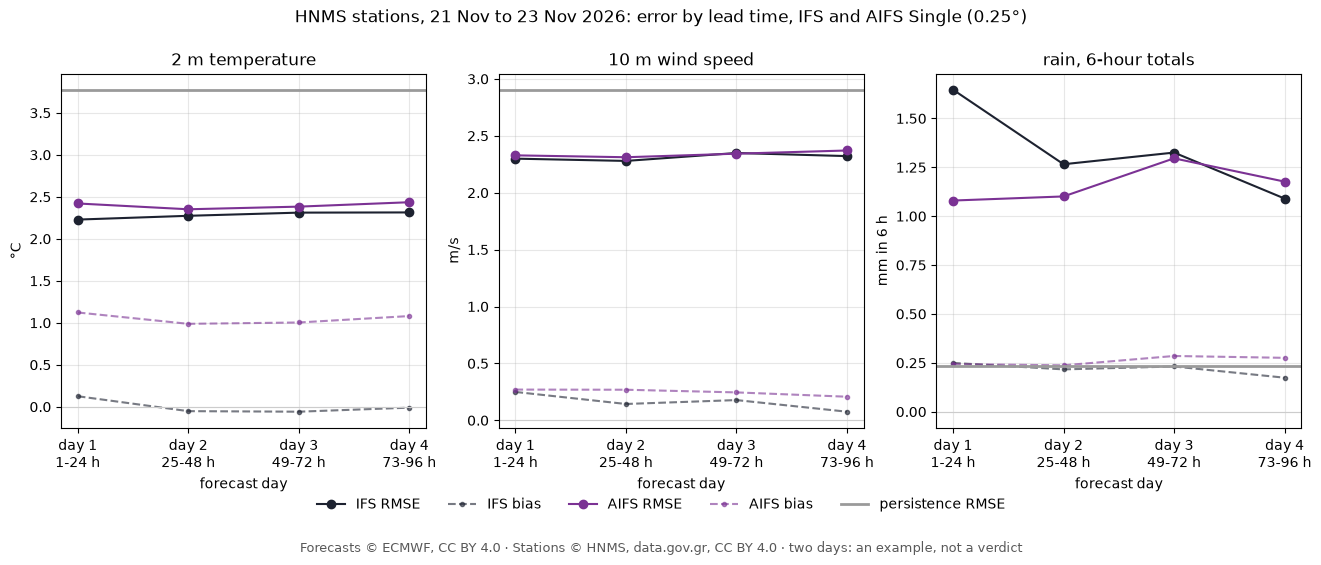

Skill against persistence (1 = perfect, 0 = no better than yesterday's weather):


1-24 h  25-48 h  49-72 h  73-96 h
t2m  AIFS    0.59     0.61     0.60     0.58
     IFS     0.65     0.64     0.63     0.63
wind AIFS    0.36     0.38     0.36     0.34
     IFS     0.38     0.39     0.35     0.37

In [9]:
# by forecast day (day 1 = leads 1-24 h, ...): every day holds all hours, so the day-night cycle averages out
P["day"] = (P.lead - 1) // 24 + 1
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (var, unit, title) in zip(axs, (("t2m", "°C", "2 m temperature"), ("wind", "m/s", "10 m wind speed"),
                                        ("rain", "mm in 6 h", "rain, 6-hour totals"))):
    d = P[P["var"] == var]
    for name in MODELS:
        g = d[d.model == name].groupby("day").err
        ax.plot(g.apply(lambda e: np.sqrt((e ** 2).mean())), "o-", color=COLOURS[name], label=f"{name} RMSE")
        ax.plot(g.mean(), "o--", color=COLOURS[name], alpha=0.6, ms=3, label=f"{name} bias")
    pe = d[d.model == "IFS"].dropna(subset=["pers"])
    ax.axhline(np.sqrt(((pe.pers - pe.ob) ** 2).mean()), color=COLOURS["persistence"], lw=2, label="persistence RMSE")
    ax.axhline(0, color="0.8", lw=0.8)
    ax.set_title(title); ax.set_xlabel("forecast day"); ax.set_ylabel(unit); ax.grid(alpha=0.3)
    days = sorted(d.day.unique()); ax.set_xticks(days, [f"day {k}\n{24 * k - 23}-{24 * k} h" for k in days])
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.suptitle(f"HNMS stations, {START:%d %b} to {END:%d %b %Y}: error by lead time, IFS and AIFS Single (0.25°)", y=1.02)
fig.text(0.5, -0.16, "Forecasts © ECMWF, CC BY 4.0 · Stations © HNMS, data.gov.gr, CC BY 4.0 · two days: an example, "
         "not a verdict", ha="center", fontsize=9, color="0.35")
plt.savefig("hnms_scores.png", dpi=120, bbox_inches="tight"); plt.show()

skill = {}
for (var, name), d in P[P["var"] != "rain"].dropna(subset=["pers"]).groupby(["var", "model"]):
    for lead, e in d.groupby(pd.cut(d.lead, [0, 24, 48, 72, 96, 240], labels=["1-24 h", "25-48 h", "49-72 h", "73-96 h", "97 h+"]),
                             observed=True):
        skill[var, name, lead] = 1 - (e.err ** 2).mean() / ((e.pers - e.ob) ** 2).mean()
print("Skill against persistence (1 = perfect, 0 = no better than yesterday's weather):")
pd.Series(skill).unstack().round(2)

Two days hold only a few runs per lead time, so the lines are noisy; ECMWF's published scores show the smooth
version over months. Rain RMSE is dominated by the few rainy hours: over a mostly dry spell even "yesterday's weather"
can beat a model on RMSE, by forecasting no rain. That is why section 6 scores rain as events.

## 5 · When and where?

The error is rarely the same at all hours and all places. Night-time inversions, sea breezes and mountains each
leave their own mark. These two tables break the temperature and wind errors down by **hour of day** and by **kind
of station** (mountain: 500 m or higher; coast: sea within about 25 km and below 100 m; inland: the rest).

In [10]:
d = P[P["var"] != "rain"].copy(); d["hour (UTC)"] = d.valid.dt.hour
by_hour = d.groupby(["var", "model", "hour (UTC)"]).err.agg(bias="mean", RMSE=lambda e: np.sqrt((e ** 2).mean()))
display(by_hour.unstack("hour (UTC)").round(2))
by_kind = d.groupby(["var", "model", "kind"]).agg(stations=("id", "nunique"), bias=("err", "mean"),
                                                 RMSE=("err", lambda e: np.sqrt((e ** 2).mean())))
by_kind.round(2)

bias                    RMSE                  
hour (UTC)    0     6     12    18    0     6     12    18
var  model                                                
t2m  AIFS   1.44  1.11  0.28  1.76  2.85  2.61  1.53  2.73
     IFS    0.29  0.33 -0.62  0.33  2.73  2.68  1.56  2.29
wind AIFS   0.48  0.34 -0.10  0.44  2.22  2.58  2.48  1.95
     IFS    0.21  0.20  0.14  0.11  2.20  2.62  2.42  1.89

stations  bias  RMSE
var  model kind                          
t2m  AIFS  coast           45  1.01  2.43
           inland          19  1.09  2.35
           mountain         7  1.19  2.35
     IFS   coast           45 -0.04  2.30
           inland          19  0.18  2.15
           mountain         7 -0.25  2.52
wind AIFS  coast           44  0.30  2.31
           inland          19  0.50  2.37
           mountain         7 -0.79  2.44
     IFS   coast           44  0.12  2.31
           inland          19  0.57  1.91
           mountain         7 -0.66  3.16

## 6 · Did it catch the events? Yes/no scores for rain and wind

For rain, and for wind warnings, what matters is often **whether the event happened**, not its exact amount. Each
forecast-observation pair falls into one box of a 2×2 table: **hit** (forecast yes, observed yes), **miss**,
**false alarm**, or **correct no**. From the table:

| Score | Meaning | Perfect |
|---|---|---|
| POD, probability of detection | share of observed events that were forecast | 1 |
| FAR, false alarm ratio | share of forecast events that did not happen | 0 |
| Frequency bias | forecast events ÷ observed events (above 1: forecasts it too often) | 1 |
| ETS, equitable threat score | hits beyond those expected by chance; robust for rare events | 1 (0 = chance) |

Rain events at a point are rare, so **two days give few events**: treat these numbers as a demonstration of the
method and add more days (section 8) before reading anything into them.

In [11]:
def contingency(fc_yes, ob_yes):
    a = int((fc_yes & ob_yes).sum()); b = int((fc_yes & ~ob_yes).sum())
    c = int((~fc_yes & ob_yes).sum()); n = len(fc_yes); d = n - a - b - c
    ar = (a + b) * (a + c) / n if n else np.nan
    return {"observed events": a + c, "hits": a, "misses": c, "false alarms": b,
            "POD": a / (a + c) if a + c else np.nan, "FAR": b / (a + b) if a + b else np.nan,
            "frequency bias": (a + b) / (a + c) if a + c else np.nan,
            "ETS": (a - ar) / (a + b + c - ar) if (a + b + c - ar) else np.nan}

events = {}
for name in MODELS:
    r = P[(P["var"] == "rain") & (P.model == name)]
    for th in RAIN:
        events[f"rain ≥ {th} mm / 6 h", name] = contingency(r.fc >= th, r.ob >= th)
    w = P[(P["var"] == "wind") & (P.model == name)]
    events[f"wind ≥ {WIND} m/s", name] = contingency(w.fc >= WIND, w.ob >= WIND)
pd.DataFrame(events).T.round(2)

,,observed events,hits,misses,false alarms,POD,FAR,frequency bias,ETS
rain ≥ 1 mm / 6 h,IFS,12.0,4.0,8.0,125.0,0.33,0.97,10.75,0.02
rain ≥ 5 mm / 6 h,IFS,0.0,0.0,0.0,25.0,NaN,1.00,NaN,0.00
wind ≥ 8 m/s,IFS,156.0,59.0,97.0,102.0,0.38,0.63,1.03,0.20
rain ≥ 1 mm / 6 h,AIFS,12.0,8.0,4.0,156.0,0.67,0.95,13.67,0.04
rain ≥ 5 mm / 6 h,AIFS,0.0,0.0,0.0,40.0,NaN,1.00,NaN,0.00
wind ≥ 8 m/s,AIFS,156.0,57.0,99.0,93.0,0.37,0.62,0.96,0.20


Model wind at 0.25° is an average over a 25 km box, so it rarely reaches the speeds an exposed anemometer
measures: expect a frequency bias below 1 for strong winds. Rain at a point against a 25 km box has the same problem
the other way round: the model spreads light rain over the whole box. Both are why services calibrate model output
to their own stations.

## 7 · How good were the probabilities? IFS ENS and AIFS ENS

ECMWF runs two ensembles, physics-based (**IFS ENS**) and machine-learned (**AIFS ENS**), both open
data. An ensemble is scored differently:

- **CRPS**, the continuous ranked probability score: the ensemble version of the absolute error, in °C. It rewards a
  forecast that is both close and sharp. For a single forecast it equals the absolute error, so it can be compared
  with the MAE of a single member on its own.
- **Spread against error:** in a reliable ensemble, the spread of the members matches the error of the ensemble mean.
  Spread too small = overconfident.
- **Rank histogram:** where the observation falls among the sorted members. Flat is reliable; U-shaped means the
  observations often fall outside the ensemble (too little spread); a slope means a bias.

One run, 2 m temperature, at 12 UTC on each day of the period. The download is the biggest step (about 80 MB per ensemble).

In [12]:
ENS_RUN = (START - pd.Timedelta(hours=24)).normalize()                      # leads 24 h onwards
ENS_STEPS = [s for s in range(12, 241, 24) if START <= ENS_RUN + pd.Timedelta(hours=s) <= END]   # 12 UTC each day
ens = {}
for name, model in (("IFS ENS", "ifs"), ("AIFS ENS", "aifs-ens")):
    print(f"{name} {ENS_RUN:%d %b} 00 UTC, steps {ENS_STEPS}")
    # the 50 perturbed members (the IFS control is not in the 0.25° open data, so both are scored on 50)
    F = read(get(f"{model}_ens_pf.grib2", date=ENS_RUN.to_pydatetime(), time=0, stream="enfo", type="pf",
                 levtype="sfc", model=model, step=ENS_STEPS, param="2t"))[0]
    ens[name] = {k: v for k, v in F.items() if k[2] >= 1}
GRID = {"IFS ENS": fc["IFS", "grid"], "AIFS ENS": fc["AIFS", "grid"]}       # same 0.25° grid; height from the parent model

def crps(x, y):
    """fair CRPS of an ensemble x (members) for observation y"""
    m = len(x)
    return np.abs(x - y).mean() - np.abs(x[:, None] - x[None, :]).sum() / (2 * m * (m - 1))

E = []
for name, F in ens.items():
    g = GRID[name]
    for st in stations.itertuples():
        j, i = grid_point(st.lat, st.lon, g); dz = LAPSE * (g["z"][j, i] - st.elev_m)
        for s in ENS_STEPS:
            v = ENS_RUN + pd.Timedelta(hours=s); y = ob.get((st.id, v), {}).get("t")
            members = np.array([F[k][j, i] for k in sorted(F) if k[1] == s]) - 273.15 + dz
            first = F["2t", s, 1][j, i] - 273.15 + dz                         # one member alone, as a single forecast
            if y is None or np.isnan(y) or len(members) < 2: continue
            E.append(dict(model=name, id=st.id, lead=s, ob=y, crps=crps(members, y), mean=members.mean(),
                          spread=members.std(ddof=1), single=first,
                          rank=int((members < y).sum()), members=len(members)))
E = pd.DataFrame(E)
print(f"{len(E):,} ensemble forecasts scored, {E.members.max()} members each")
E.groupby("model").apply(lambda d: pd.Series({
    "CRPS (°C)": d.crps.mean(), "MAE of one member (°C)": (d.single - d.ob).abs().mean(),
    "RMSE ensemble mean (°C)": np.sqrt(((d["mean"] - d.ob) ** 2).mean()), "mean spread (°C)": d.spread.mean()})).round(2)

IFS ENS 20 Nov 00 UTC, steps [36, 60, 84]


AIFS ENS 20 Nov 00 UTC, steps [36, 60, 84]


424 ensemble forecasts scored, 50 members each


,CRPS (°C),MAE of one member (°C),RMSE ensemble mean (°C),mean spread (°C)
model,,,,
AIFS ENS,0.88,1.21,1.51,0.70
IFS ENS,0.99,1.28,1.49,0.48


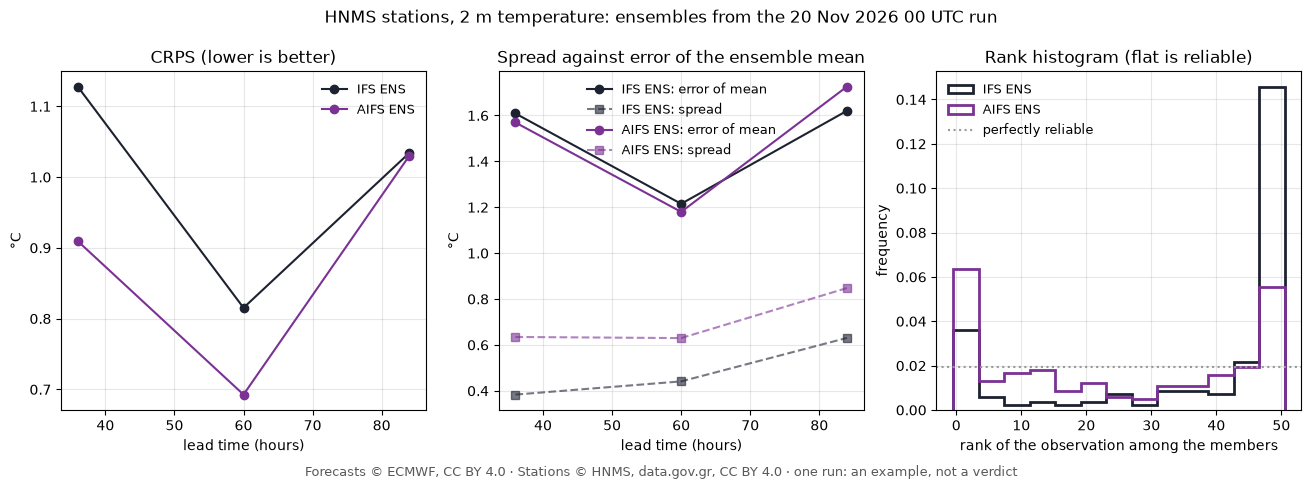

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
for name, c in (("IFS ENS", COLOURS["IFS"]), ("AIFS ENS", COLOURS["AIFS"])):
    d = E[E.model == name]; g = d.groupby("lead")
    axs[0].plot(g.crps.mean(), "o-", color=c, label=name)
    axs[1].plot(g.apply(lambda x: np.sqrt(((x["mean"] - x.ob) ** 2).mean())), "o-", color=c, label=f"{name}: error of mean")
    axs[1].plot(g.spread.mean(), "s--", color=c, alpha=0.6, label=f"{name}: spread")
    m = d.members.max(); bins = np.linspace(-0.5, m + 0.5, 14)
    axs[2].hist(d["rank"], bins=bins, density=True, histtype="step", lw=2, color=c, label=name)
axs[2].axhline(1 / (d.members.max() + 1), color="0.6", ls=":", label="perfectly reliable")
axs[0].set(title="CRPS (lower is better)", xlabel="lead time (hours)", ylabel="°C")
axs[1].set(title="Spread against error of the ensemble mean", xlabel="lead time (hours)", ylabel="°C")
axs[2].set(title="Rank histogram (flat is reliable)", xlabel="rank of the observation among the members", ylabel="frequency")
for ax in axs: ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=9)
fig.suptitle(f"HNMS stations, 2 m temperature: ensembles from the {ENS_RUN:%d %b %Y} 00 UTC run", y=1.02)
fig.text(0.5, -0.04, "Forecasts © ECMWF, CC BY 4.0 · Stations © HNMS, data.gov.gr, CC BY 4.0 · one run: an example, "
         "not a verdict", ha="center", fontsize=9, color="0.35")
plt.savefig("hnms_ens_scores.png", dpi=120, bbox_inches="tight"); plt.show()

Raw ensembles at station points are usually **under-dispersive** (U-shaped histogram): the members are 25 km
boxes and share the model's view of the valley or the coast, while the station sees its own. Part of that is not a
model fault but representativeness, which is why the spread is often compared after a simple local bias correction.

## 8 · Your turn: more days, other runs 🌍

Two days show how the scores work; **a choice of model needs weeks to months**, and ideally each season.

- **Longer periods:** set `DAYS = 14` (or 30) in the settings and run again. Older forecasts come from the cloud
  mirrors of ECMWF open data, which keep the 0.25° archive back to 2023 (AIFS Single from 2025). Each station file
  holds 5-minute records from April 2026, so the stations allow that far back.
- **An earlier period:** set `END = "2026-08-28T18:00"` to score the hottest week of the summer.
- **Calibrate, then score again:** subtract each station's mean error from section 3 and re-run sections 4 to 7. What
  is left is the part a local calibration cannot fix.
- **Other variables:** the HNMS files also hold relative humidity, pressure and gusts (`Wind_Speed_Max_5min`;
  the IFS has `10fg`, the 10 m gust).
- **Keep it running:** run the notebook every day and append the pair table (`P`) to a file: after a season you have
  your own verification of IFS against AIFS at your own stations.
- **More scores:** [earthkit-meteo](https://github.com/ecmwf/earthkit-meteo) and the WMO/WWRP
  [verification methods page](https://www.cawcr.gov.au/projects/verification/) cover many more (SEDI for rare
  events, Brier score and reliability diagrams for probabilities, spatial scores such as FSS).

### Data & licence
**ECMWF open data**, CC BY 4.0: `© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`.
**HNMS station data**, CC BY 4.0: `© HNMS (Hellenic National Meteorological Service) · Source: data.gov.gr`.
No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) ·
[ECMWF forecast quality](https://www.ecmwf.int/en/forecasts/quality-our-forecasts) · [HNMS](https://www.emy.gr) ·
[data.gov.gr](https://data.gov.gr) · [earthkit](https://earthkit.ecmwf.int)